# 01 — El audio

**Objetivo:** entender qué es una grabación digital antes de hacerle nada.
Al terminar deberías poder explicar:
- qué es la frecuencia de muestreo y por qué limita qué frecuencias "existen" en el audio;
- qué muestra una forma de onda y qué muestra un espectrograma;
- en qué rango de frecuencias está la energía de los sonidos cardíacos y pulmonares.

Esto último es la base de la notebook 02: si sabemos dónde está la energía útil,
sabemos qué filtro tiene sentido aplicar.

In [1]:
import sys
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.features import normalize_lung_id
from src.paths import AUDIO, DATA_DIR

## 1. Los metadatos

Cada grabación tiene un ID con el formato `género_tipo_foco`, por ejemplo
`F_N_RC` = femenino, normal, foco RC. Los IDs pulmonares del metadato no
coinciden con los nombres de archivo para los crepitantes (`G`/`C` en el CSV,
`CC`/`FC` en disco); `normalize_lung_id` lo corrige (sección 6.7 de la tesis).

In [2]:
hs = pd.read_csv(DATA_DIR / "HS.csv")
ls = pd.read_csv(DATA_DIR / "LS.csv")
ls["Lung Sound ID"] = ls["Lung Sound ID"].map(normalize_lung_id)

print(hs["Heart Sound Type"].value_counts(), "\n")
print(ls["Lung Sound Type"].value_counts())

Heart Sound Type
Normal                   9
Mid Systolic Murmur      7
Late Diastolic Murmur    6
Early Systolic Murmur    6
S3                       5
Late Systolic Murmur     5
Atrial Fibrillation      4
Tachycardia              3
AV Block                 3
S4                       2
Name: count, dtype: int64 

Lung Sound Type
Normal             12
Pleural Rub         9
Coarse Crackles     9
Rhonchi             8
Wheezing            7
Fine Crackles       5
Name: count, dtype: int64


In [3]:
def ruta(subset, tipo):
    """Ruta del primer archivo de un tipo de sonido dado ('HS' o 'LS')."""
    meta, col_tipo, col_id = ((hs, "Heart Sound Type", "Heart Sound ID") if subset == "HS"
                              else (ls, "Lung Sound Type", "Lung Sound ID"))
    file_id = meta.loc[meta[col_tipo] == tipo, col_id].iloc[0]
    return AUDIO[subset] / f"{file_id}.wav"

## 2. Cargar una grabación: muestras y frecuencia de muestreo

Un audio digital es una lista de números: la amplitud de la señal medida
muchas veces por segundo. Cuántas veces por segundo es la **frecuencia de
muestreo** (`sr`, *sample rate*), en Hz.

`sr=None` le pide a librosa que respete la frecuencia original del archivo.

In [4]:
f = ruta("HS", "Normal")
y, sr = librosa.load(f, sr=None)
print(f"Archivo: {f.name}")
print(f"Frecuencia de muestreo: {sr} Hz")
print(f"Cantidad de muestras: {len(y)}  ->  duración = {len(y)} / {sr} = {len(y) / sr:.1f} s")
print(f"Primeras 10 muestras: {np.round(y[:10], 4)}")

Archivo: F_N_RC.wav
Frecuencia de muestreo: 4000 Hz
Cantidad de muestras: 60000  ->  duración = 60000 / 4000 = 15.0 s
Primeras 10 muestras: [-0.0024 -0.0025 -0.0025 -0.0024 -0.0023 -0.002  -0.0018 -0.0016 -0.0014
 -0.0013]


### El límite de Nyquist

Con `sr` muestras por segundo solo se pueden representar frecuencias de hasta
`sr / 2` (la **frecuencia de Nyquist**). Para ver una oscilación hacen falta
al menos dos muestras por ciclo: una arriba y una abajo.

Los archivos de HLS-CMDS están a **4000 Hz**, así que contienen información
solo hasta **2000 Hz**. Para sonidos cardíacos (casi todo por debajo de unos
cientos de Hz) alcanza de sobra.

**Ojo con lo que hace el código actual:** `src/features.py` carga a 22.050 Hz.
Eso *remuestrea* (interpola muestras nuevas), pero no puede inventar
información: entre 2000 y 11.025 Hz el audio queda vacío. Lo comprobamos:

**Nota (prefiltrado del dataset): de dónde salen los 4000 Hz.** Según el paper del dataset (Torabi et al., 2025, Tabla I), el estetoscopio graba a 22.050 Hz, pero los archivos publicados están todos a 4000 Hz: se remuestrearon hacia abajo antes de publicarlos. Lo que había por encima de 2000 Hz se perdió en ese paso, y volver a cargarlos a 22.050 Hz no lo recupera.

Remuestreado: 330750 muestras a 22050 Hz (antes 60000 a 4000 Hz)


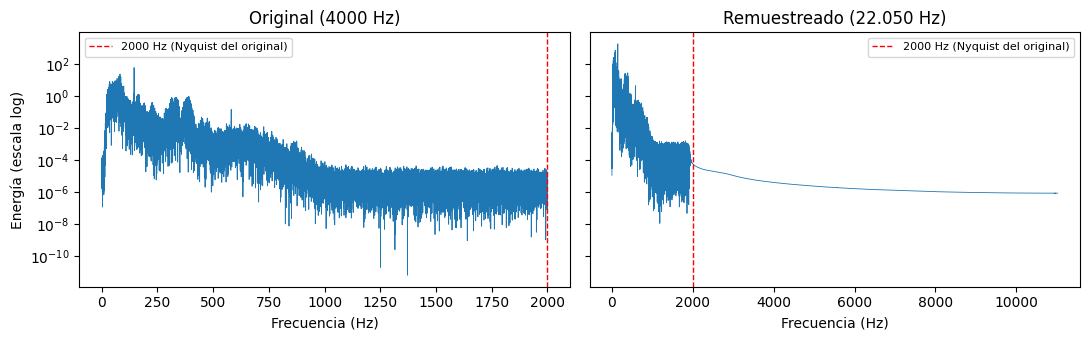

In [5]:
y22, sr22 = librosa.load(f, sr=22050)
print(f"Remuestreado: {len(y22)} muestras a {sr22} Hz (antes {len(y)} a {sr} Hz)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (senal, fs, titulo) in zip(axes, [(y, sr, "Original (4000 Hz)"),
                                           (y22, sr22, "Remuestreado (22.050 Hz)")]):
    espectro = np.abs(np.fft.rfft(senal)) ** 2
    freqs = np.fft.rfftfreq(len(senal), 1 / fs)
    ax.semilogy(freqs, espectro + 1e-12, lw=0.6)
    ax.axvline(2000, color="red", ls="--", lw=1, label="2000 Hz (Nyquist del original)")
    ax.set(title=titulo, xlabel="Frecuencia (Hz)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Energía (escala log)")
fig.tight_layout()

A la derecha, todo lo que está a la derecha de la línea roja es prácticamente
cero: no hay sonido ahí. Más adelante (notebook 03) vamos a ver que varias
features (los MFCC, el centroide espectral) "miran" ese rango vacío.

## 3. Escuchar

Antes de mirar gráficos, conviene escuchar. Con auriculares se nota más.

In [6]:
for tipo in ["Normal", "Mid Systolic Murmur", "Atrial Fibrillation"]:
    print(tipo)
    yy, ss = librosa.load(ruta("HS", tipo), sr=None)
    display(Audio(yy, rate=ss))

Normal


Mid Systolic Murmur


Atrial Fibrillation


## 4. La forma de onda: amplitud en el tiempo

El eje horizontal es el tiempo y el vertical, la amplitud. En un sonido
cardíaco normal deberían verse los "golpes" de R1 y R2 separados por
silencios. Mostramos 4 segundos para que se distingan.

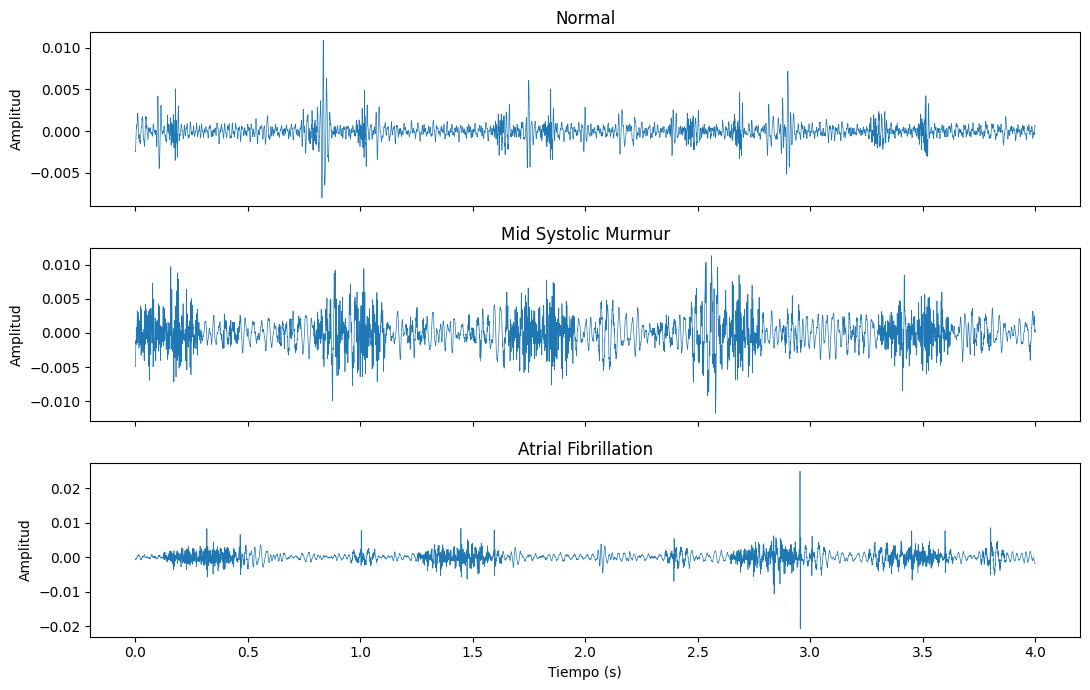

In [7]:
TIPOS_HS = ["Normal", "Mid Systolic Murmur", "Atrial Fibrillation"]
SEGUNDOS = 4

fig, axes = plt.subplots(len(TIPOS_HS), 1, figsize=(11, 7), sharex=True)
for ax, tipo in zip(axes, TIPOS_HS):
    yy, ss = librosa.load(ruta("HS", tipo), sr=None)
    t = np.arange(len(yy)) / ss
    n = SEGUNDOS * ss
    ax.plot(t[:n], yy[:n], lw=0.5)
    ax.set(title=tipo, ylabel="Amplitud")
axes[-1].set_xlabel("Tiempo (s)")
fig.tight_layout()

Qué buscar:
- **Normal:** pares de golpes (R1-R2) regulares.
- **Soplo:** "relleno" entre los golpes (el flujo turbulento).
- **Fibrilación auricular:** golpes a intervalos irregulares.

Esta última diferencia es de **ritmo**, no de "timbre". Tenelo presente: las
features actuales resumen toda la grabación en promedios y pierden la
secuencia temporal (sección 2.7.3 de la tesis).

## 5. El espectrograma: frecuencia en el tiempo

El espectrograma corta el audio en ventanas cortas y calcula cuánta energía
hay en cada frecuencia en cada ventana (transformada de Fourier de tiempo
corto, STFT). Eje horizontal: tiempo. Eje vertical: frecuencia. Color: energía.

Parámetros:
- `n_fft`: largo de cada ventana en muestras. 256 muestras a 4000 Hz = 64 ms.
  Ventanas más largas dan más detalle en frecuencia y menos en tiempo.
- `hop_length`: cuánto se corre la ventana cada vez (64 muestras = 16 ms).

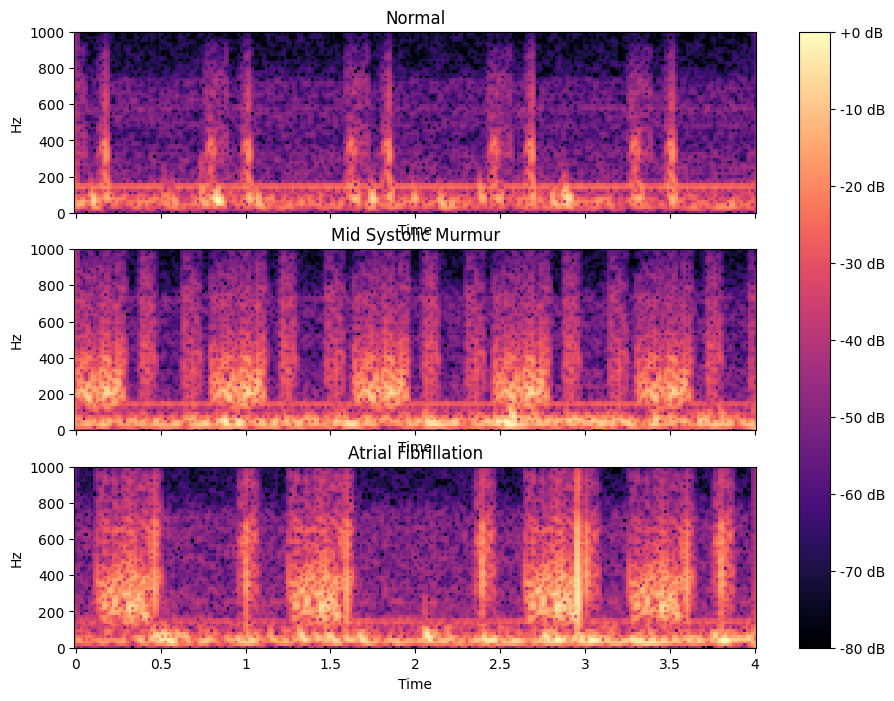

In [8]:
N_FFT, HOP = 256, 64

fig, axes = plt.subplots(len(TIPOS_HS), 1, figsize=(11, 8), sharex=True)
for ax, tipo in zip(axes, TIPOS_HS):
    yy, ss = librosa.load(ruta("HS", tipo), sr=None)
    S = librosa.amplitude_to_db(np.abs(librosa.stft(yy[:SEGUNDOS * ss], n_fft=N_FFT, hop_length=HOP)),
                                ref=np.max)
    img = librosa.display.specshow(S, sr=ss, hop_length=HOP, x_axis="time", y_axis="hz", ax=ax)
    ax.set(title=tipo, ylim=(0, 1000))
fig.colorbar(img, ax=axes, format="%+2.0f dB")

Limitamos el eje a 1000 Hz porque arriba casi no hay nada. Fijate que la
energía de los ruidos cardíacos está pegada abajo, en las frecuencias graves.

## 6. Lo mismo para sonidos pulmonares

- **Murmullo vesicular normal:** ruido suave, más intenso en la inspiración.
- **Sibilancias (wheezing):** líneas horizontales en el espectrograma, porque
  son tonos sostenidos ("musicales").
- **Crepitantes:** líneas verticales finas, porque son chasquidos muy breves.

['Normal' 'Pleural Rub' 'Rhonchi' 'Wheezing' 'Fine Crackles'
 'Coarse Crackles']


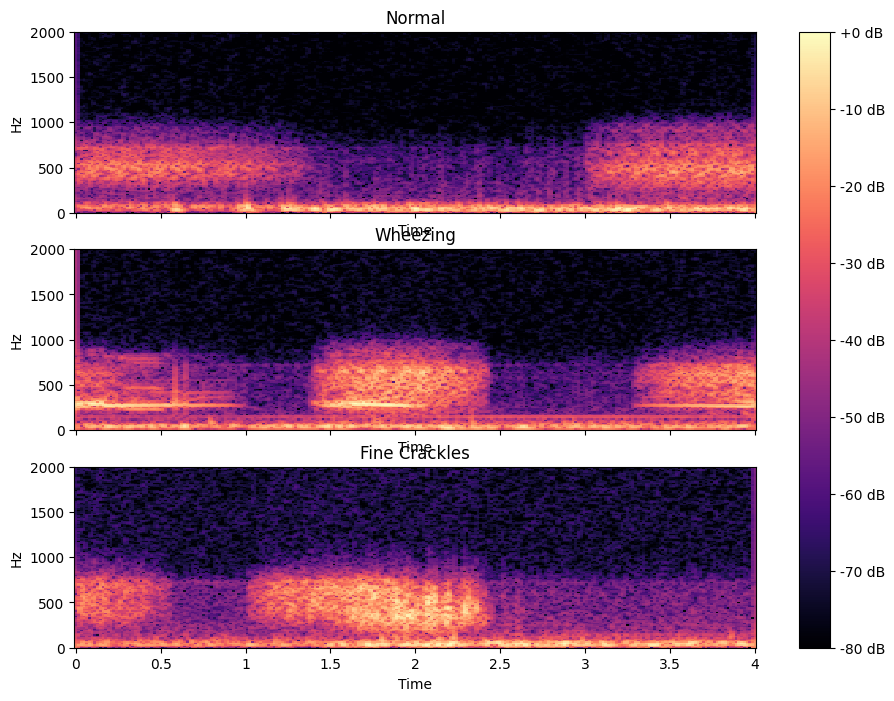

In [9]:
TIPOS_LS = ["Normal", "Wheezing", "Fine Crackles"]
print(ls["Lung Sound Type"].unique())   # verificar que los nombres coinciden

fig, axes = plt.subplots(len(TIPOS_LS), 1, figsize=(11, 8), sharex=True)
for ax, tipo in zip(axes, TIPOS_LS):
    yy, ss = librosa.load(ruta("LS", tipo), sr=None)
    display(Audio(yy, rate=ss))
    S = librosa.amplitude_to_db(np.abs(librosa.stft(yy[:SEGUNDOS * ss], n_fft=N_FFT, hop_length=HOP)),
                                ref=np.max)
    img = librosa.display.specshow(S, sr=ss, hop_length=HOP, x_axis="time", y_axis="hz", ax=ax)
    ax.set(title=tipo, ylim=(0, 2000))
fig.colorbar(img, ax=axes, format="%+2.0f dB")

Espectrograma:

1. El color es la amplitud de esa frecuencia en ese momento. No es el volumen total del sonido. Un punto del espectrograma responde: "en este instante (eje x), ¿cuánta energía hay en esta frecuencia (eje y)?". Por eso un mismo instante puede tener una zona brillante abajo (graves fuertes) y oscura arriba (agudos casi ausentes).

2. Los decibeles son relativos al punto más fuerte. En el código aparece ref=np.max. Eso hace que:

0 dB sea el punto más intenso de toda la imagen;
todo lo demás sea negativo: cuánto más débil es respecto de ese máximo.
Por eso la barra de colores va de 0 hacia abajo (-20, -40, -60...). No son decibeles "absolutos" como los de un sonómetro.

3. Por qué decibeles y no la amplitud directa. Es una escala logarítmica:

-20 dB = 10 veces menos amplitud;
-40 dB = 100 veces menos;
-60 dB = 1000 veces menos.
En un sonido conviven componentes muy fuertes (el R1) y muy débiles (un soplo suave, un R3). En escala lineal, los débiles quedarían todos negros y no los verías. La escala en dB "comprime" ese rango y deja ver ambos a la vez. Además se parece a cómo percibe el oído, que también es logarítmico.

Así que, leyendo un espectrograma cardíaco normal, vas a ver manchas brillantes cortas y verticales pegadas abajo (R1 y R2: breves y graves) separadas por zonas oscuras (los silencios). En un soplo, esas zonas oscuras entre ruidos se "rellenan" de color

## 7. ¿Dónde está la energía? (la pregunta clave para elegir un filtro)

Para cada grabación calculamos qué porcentaje de su energía total está por
debajo de cada frecuencia (energía acumulada), y promediamos por subconjunto.
Si, por ejemplo, el 95 % de la energía cardíaca está por debajo de 300 Hz, un
filtro pasa bajo en ~300 Hz conservaría casi todo el sonido cardíaco y
eliminaría el resto.

Cardíacos (HS): el 95 % de la energía está por debajo de 360 Hz (promedio)
Pulmonares (LS): el 95 % de la energía está por debajo de 640 Hz (promedio)


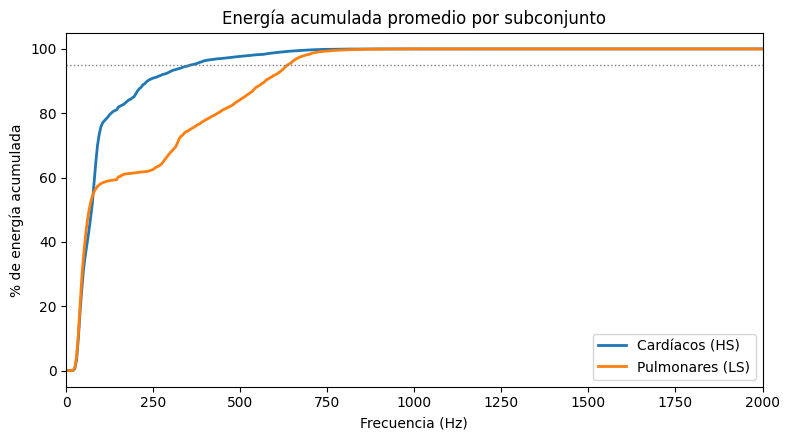

In [10]:
def energia_acumulada(path, freqs_grilla):
    """Fracción de la energía total por debajo de cada frecuencia de la grilla."""
    yy, ss = librosa.load(path, sr=None)
    espectro = np.abs(np.fft.rfft(yy)) ** 2
    freqs = np.fft.rfftfreq(len(yy), 1 / ss)
    acum = np.cumsum(espectro) / espectro.sum()
    return np.interp(freqs_grilla, freqs, acum)


grilla = np.arange(0, 2001, 5)
curvas = {"Cardíacos (HS)": [energia_acumulada(p, grilla) for p in sorted(AUDIO["HS"].glob("*.wav"))],
          "Pulmonares (LS)": [energia_acumulada(p, grilla) for p in sorted(AUDIO["LS"].glob("*.wav"))]}

fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, cs in curvas.items():
    media = np.mean(cs, axis=0)
    ax.plot(grilla, 100 * media, lw=2, label=nombre)
    corte = grilla[np.argmax(media >= 0.95)]
    print(f"{nombre}: el 95 % de la energía está por debajo de {corte} Hz (promedio)")
ax.axhline(95, color="gray", ls=":", lw=1)
ax.set(xlabel="Frecuencia (Hz)", ylabel="% de energía acumulada", xlim=(0, 2000),
       title="Energía acumulada promedio por subconjunto")
ax.legend()
fig.tight_layout()

**Nota (prefiltrado del dataset): cómo interpretar este resultado.** Las grabaciones vienen filtradas por el propio estetoscopio, con un modo distinto según el subconjunto (Torabi et al., 2025, Tabla I):

| Subconjunto | Modo | Respuesta |
|---|---|---|
| Cardíacos | Campana (*Bell*) | 20–200 Hz, caída fuerte por encima de 300 Hz |
| Pulmonares | Diafragma | 100–500 Hz, caída por debajo de 200 Hz |
| Mezclas | *Midrange* | 50–500 Hz, refuerzo de +20 dB en 550 Hz |

Además aplicaron un pasa banda por software (cortes no informados).

Por eso, que el 95 % de la energía cardíaca esté por debajo de ~360 Hz y la pulmonar por debajo de ~640 Hz **no describe solo la fisiología**: describe el sonido *tal como lo grabó este equipo con ese modo*. Por ejemplo, la parte aguda de algunos soplos (por encima de 300 Hz) ya llega atenuada. Y como cardíacos y pulmonares se grabaron con filtros distintos, compararlos entre sí tiene esa limitación.

## 8. Tu turno

Cambiá `TIPO_ELEGIDO` por cualquier tipo de la lista de la sección 1 (por
ejemplo `"S3"`, `"AV Block"`, `"Coarse Crackles"`), escuchalo y miralo.

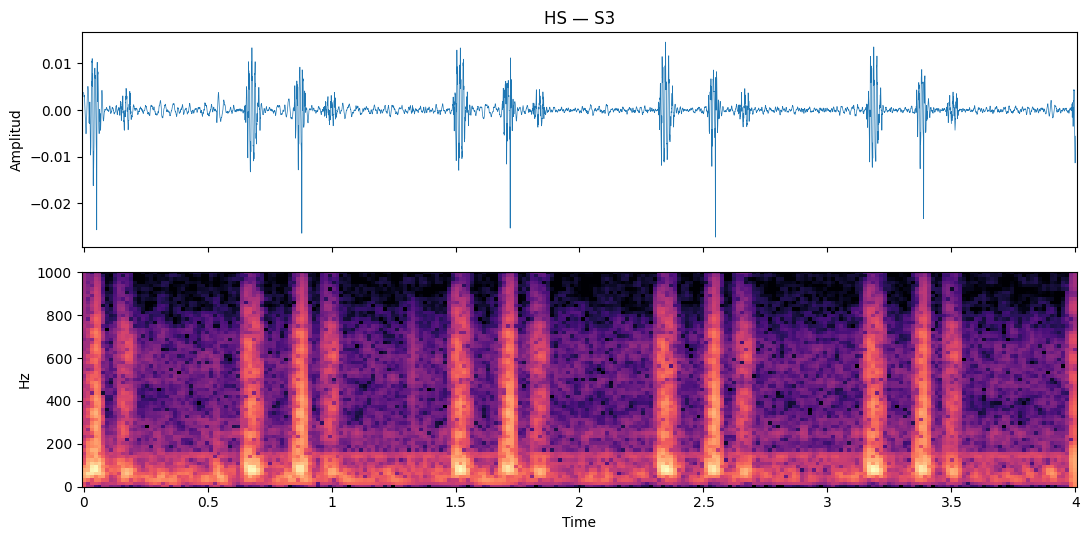

In [11]:
SUBSET, TIPO_ELEGIDO = "HS", "S3"

yy, ss = librosa.load(ruta(SUBSET, TIPO_ELEGIDO), sr=None)
display(Audio(yy, rate=ss))
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(np.arange(SEGUNDOS * ss) / ss, yy[:SEGUNDOS * ss], lw=0.5)
axes[0].set(title=f"{SUBSET} — {TIPO_ELEGIDO}", ylabel="Amplitud")
S = librosa.amplitude_to_db(np.abs(librosa.stft(yy[:SEGUNDOS * ss], n_fft=N_FFT, hop_length=HOP)), ref=np.max)
librosa.display.specshow(S, sr=ss, hop_length=HOP, x_axis="time", y_axis="hz", ax=axes[1])
axes[1].set(ylim=(0, 1000))
fig.tight_layout()

## Preguntas de control

1. Si un archivo tiene `sr = 4000`, ¿cuál es la frecuencia más alta que puede
   contener? ¿Por qué cargarlo a 22.050 Hz no agrega información?
2. ¿Qué diferencia hay entre la forma de onda y el espectrograma? ¿Cuál usarías
   para ver una arritmia y cuál para ver una sibilancia?
3. ¿Por qué una sibilancia se ve como una línea horizontal y un crepitante como
   una línea vertical?
4. Según la sección 7, ¿por debajo de qué frecuencia está casi toda la energía
   cardíaca? ¿Y la pulmonar? ¿Qué corte de filtro pasa bajo propondrías para
   cada uno, y qué te preocuparía perder?
5. ¿Qué relación hay entre un filtro pasa bajo y la campana del estetoscopio?

**Nota (prefiltrado del dataset), para la pregunta 5:** los cardíacos de este dataset se grabaron literalmente en el modo *campana* del estetoscopio digital, y los pulmonares en modo *diafragma*. Es decir, el filtro que te pregunta la pregunta 5 ya está aplicado en los datos.

1. Si un archivo tiene sr = 4000, ¿cuál es la frecuencia más alta que puede contener? ¿Por qué cargarlo a 22.050 Hz no agrega información?

Hasta 2000 Hz, la mitad de la frecuencia de muestreo (límite de Nyquist): para captar una oscilación hacen falta al menos dos mediciones por ciclo.

Cargarlo a 22.050 Hz no agrega información porque las muestras nuevas se calculan interpolando entre las que ya existían. El grabador nunca midió nada por encima de 2000 Hz, así que esa zona queda vacía, como se ve en el gráfico de la sección 2.

2. ¿Qué diferencia hay entre la forma de onda y el espectrograma? ¿Cuál usarías para ver una arritmia y cuál para una sibilancia?

Forma de onda: amplitud en el tiempo. Muestra cuándo pasan las cosas y con qué intensidad, pero no qué frecuencias tienen.
Espectrograma: frecuencia en el tiempo, con la energía en colores. Muestra de qué está hecho el sonido en cada momento.
Para la arritmia, la forma de onda: lo que cambia es el ritmo, el espaciado irregular entre los golpes. Para la sibilancia, el espectrograma: lo que la define es un tono sostenido en una frecuencia, y eso en la forma de onda no se distingue bien.

3. ¿Por qué una sibilancia se ve como una línea horizontal y un crepitante como una vertical?

La sibilancia es un tono musical: una frecuencia que se mantiene en el tiempo (más de 80–100 ms). Frecuencia fija y duración larga dan una línea horizontal.
El crepitante es un chasquido brevísimo (pocos milisegundos). Un evento tan corto y abrupto tiene energía en muchas frecuencias a la vez, en un solo instante. Muchas frecuencias en un instante dan una línea vertical.
Es la misma lógica de tu marco teórico (2.3): continuos frente a discontinuos.

4. ¿Por debajo de qué frecuencia está casi toda la energía cardíaca? ¿Y la pulmonar? ¿Qué corte de filtro pasa bajo propondrías, y qué te preocuparía perder?

Según la sección 7, en promedio el 95 % de la energía cardíaca está por debajo de ~360 Hz y la pulmonar por debajo de ~640 Hz.

Cardíaco: un pasa bajo en torno a 400 Hz conservaría casi todo. Preocupación: algunos soplos, sobre todo los de tono agudo como la insuficiencia aórtica, pueden extenderse a varios cientos de Hz. Si el corte es demasiado bajo podría borrar justo lo patológico. Por eso conviene probar varios cortes (por ejemplo 200, 400 y 600 Hz) y comparar.

Pulmonar: un pasa bajo en torno a 800–1000 Hz. Preocupaciones:

los crepitantes tienen energía en muchas frecuencias, y un corte bajo los "suaviza";
algunas sibilancias superan los 1000 Hz;
un pasa bajo no saca el sonido cardíaco, porque el corazón está en los graves.
En el pulmón probablemente tenga más sentido un pasa alto (por ejemplo, a partir de ~100–150 Hz) para atenuar la interferencia cardíaca, o un pasa banda que combine ambos. Esto lo vemos en la notebook 02.

Este punto no tiene una única respuesta correcta. Lo importante es que puedas justificar el corte con los datos (el 95 %) y con la clínica (qué sonido podrías perder).

5. ¿Qué relación hay entre un filtro pasa bajo y la campana del estetoscopio?

La campana funciona como un filtro pasa bajo: deja pasar los graves y atenúa los agudos. Por eso se usa para R3, R4 y el soplo de la estenosis mitral. El diafragma se comporta más bien como un pasa alto: atenúa los graves y realza los agudos, por eso se usa para R1, R2 y la insuficiencia aórtica.

Aplicar un filtro digital es hacer con la señal grabada lo mismo que hace el médico al elegir de qué lado del estetoscopio auscultar.